In [14]:
# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F

# Dataset and DataLoader
from torch.utils.data import Dataset, DataLoader
from medmnist import PathMNIST

# Data processing
import numpy as np
import pandas as pd

# Reproducibility and file management
import random
from pathlib import Path

print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)

All libraries imported successfully!
PyTorch version: 2.15.0


In [15]:
# Set random seeds
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

print("Random seed:", SEED)
print("Reproducibility settings configured!")


Random seed: 42
Reproducibility settings configured!


In [16]:
# Identify the MedVision project directory
PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

# Create a dedicated dataset directory
DATA_ROOT = PROJECT_ROOT / "data" / "medmnist"
DATA_ROOT.mkdir(parents=True, exist_ok=True)

print("Project directory:", PROJECT_ROOT)
print("Dataset directory:", DATA_ROOT)

# Load PathMNIST datasets
train_dataset = PathMNIST(
    split="train",
    root=str(DATA_ROOT),
    download=True
)

val_dataset = PathMNIST(
    split="val",
    root=str(DATA_ROOT),
    download=True
)

test_dataset = PathMNIST(
    split="test",
    root=str(DATA_ROOT),
    download=True
)

print("\nAll datasets loaded successfully!")
print("Training samples:", len(train_dataset))
print("Validation samples:", len(val_dataset))
print("Testing samples:", len(test_dataset))

Project directory: /Users/keonhowang/Desktop/MedVision
Dataset directory: /Users/keonhowang/Desktop/MedVision/data/medmnist


100%|██████████| 206M/206M [06:42<00:00, 511kB/s]    



All datasets loaded successfully!
Training samples: 89996
Validation samples: 10004
Testing samples: 7180


In [17]:
class MedVisionDataset(Dataset):

    def __init__(self, medmnist_dataset):
        self.images = medmnist_dataset.imgs
        self.labels = medmnist_dataset.labels

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):

        # Retrieve image
        image = self.images[index]

        # Convert NumPy image into PyTorch tensor
        image = torch.from_numpy(image)

        # Convert image from HWC to CHW
        image = image.permute(2, 0, 1)

        # Convert pixel values from [0, 255] to [0, 1]
        image = image.float() / 255.0

        # Convert label into integer tensor
        label = torch.tensor(
            int(self.labels[index][0]),
            dtype=torch.long
        )

        return image, label


print("MedVisionDataset class created successfully!")

MedVisionDataset class created successfully!


In [18]:
# Batch configuration
BATCH_SIZE = 64

# Create PyTorch datasets
train_data = MedVisionDataset(train_dataset)
val_data = MedVisionDataset(val_dataset)
test_data = MedVisionDataset(test_dataset)

# Create DataLoaders
train_loader = DataLoader(
    train_data,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0
)

val_loader = DataLoader(
    val_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

test_loader = DataLoader(
    test_data,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("All DataLoaders created successfully!")
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

All DataLoaders created successfully!
Training batches: 1407
Validation batches: 157
Testing batches: 113


In [19]:
# Retrieve one batch
images, labels = next(iter(train_loader))

print("Images shape:", images.shape)
print("Labels shape:", labels.shape)

print("\nImage data type:", images.dtype)
print("Label data type:", labels.dtype)

print("\nMinimum pixel value:", images.min().item())
print("Maximum pixel value:", images.max().item())

Images shape: torch.Size([64, 3, 28, 28])
Labels shape: torch.Size([64])

Image data type: torch.float32
Label data type: torch.int64

Minimum pixel value: 0.0313725508749485
Maximum pixel value: 0.9725490212440491


In [20]:
if torch.backends.mps.is_available():
    device = torch.device("mps")

elif torch.cuda.is_available():
    device = torch.device("cuda")

else:
    device = torch.device("cpu")

print("Selected device:", device)

Selected device: mps


In [21]:
class MedVisionCNN(nn.Module):

    def __init__(self, num_classes=9):
        super(MedVisionCNN, self).__init__()

        # First convolutional layer
        self.conv1 = nn.Conv2d(
            in_channels=3,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # Second convolutional layer
        self.conv2 = nn.Conv2d(
            in_channels=32,
            out_channels=64,
            kernel_size=3,
            padding=1
        )

        # Max pooling
        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # Fully connected layers
        self.fc1 = nn.Linear(64 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):

        # First convolution block
        x = self.conv1(x)
        x = F.relu(x)
        x = self.pool(x)

        # Second convolution block
        x = self.conv2(x)
        x = F.relu(x)
        x = self.pool(x)

        # Flatten feature maps
        x = torch.flatten(x, start_dim=1)

        # Classification layers
        x = self.fc1(x)
        x = F.relu(x)

        x = self.fc2(x)

        return x


print("MedVisionCNN architecture created successfully!")

MedVisionCNN architecture created successfully!


In [22]:
model = MedVisionCNN(num_classes=9)

# Move model to selected device
model = model.to(device)

print(model)

MedVisionCNN(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=3136, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=9, bias=True)
)


In [23]:
total_parameters = sum(
    parameter.numel()
    for parameter in model.parameters()
    if parameter.requires_grad
)

print("Total trainable parameters:", total_parameters)

Total trainable parameters: 422089


In [24]:
# Retrieve one batch
images, labels = next(iter(train_loader))

# Move images to selected device
images = images.to(device)

# Disable gradient calculation for this test
with torch.no_grad():
    outputs = model(images)

print("Input shape:", images.shape)
print("Output shape:", outputs.shape)

Input shape: torch.Size([64, 3, 28, 28])
Output shape: torch.Size([64, 9])


In [25]:
criterion = nn.CrossEntropyLoss()

print("Loss function:", criterion)

Loss function: CrossEntropyLoss()


In [26]:
LEARNING_RATE = 0.001

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

print("Optimizer:", optimizer)
print("Learning rate:", LEARNING_RATE)

Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)
Learning rate: 0.001


In [27]:
# Set model to training mode
model.train()

# Retrieve one batch
images, labels = next(iter(train_loader))

# Move batch to computing device
images = images.to(device)
labels = labels.to(device)

# Clear previous gradients
optimizer.zero_grad()

# Forward pass
outputs = model(images)

# Calculate loss
loss = criterion(outputs, labels)

# Backpropagation
loss.backward()

# Update model parameters
optimizer.step()

print("One training iteration completed!")
print("Batch images:", images.shape)
print("Batch labels:", labels.shape)
print("Model outputs:", outputs.shape)
print("Training loss:", loss.item())

One training iteration completed!
Batch images: torch.Size([64, 3, 28, 28])
Batch labels: torch.Size([64])
Model outputs: torch.Size([64, 9])
Training loss: 2.2088980674743652


In [28]:
# Set random seed
torch.manual_seed(SEED)

# Reinitialize the model
model = MedVisionCNN(num_classes=9).to(device)

# Configure loss function
criterion = nn.CrossEntropyLoss()

# Configure optimizer
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Model reset successfully!")
print("Device:", device)
print("Loss function:", criterion)
print("Optimizer:", optimizer)

Model reset successfully!
Device: mps
Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [29]:
def train_one_epoch(model, train_loader, criterion, optimizer, device):

    model.train()

    running_loss = 0.0
    correct_predictions = 0
    total_predictions = 0

    for images, labels in train_loader:

        images = images.to(device)
        labels = labels.to(device)

        # Clear previous gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update weights
        optimizer.step()

        # Track loss
        running_loss += loss.item() * images.size(0)

        # Calculate predictions
        _, predicted = torch.max(outputs, 1)

        # Count correct predictions
        correct_predictions += (predicted == labels).sum().item()
        total_predictions += labels.size(0)

    epoch_loss = running_loss / total_predictions
    epoch_accuracy = correct_predictions / total_predictions

    return epoch_loss, epoch_accuracy


print("Training function created successfully!")


Training function created successfully!


In [30]:
from sklearn.metrics import f1_score

def evaluate_model(model, val_loader, criterion, device):

    model.eval()

    running_loss = 0.0
    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item() * images.size(0)

            _, predicted = torch.max(outputs, 1)

            all_predictions.extend(predicted.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    validation_loss = running_loss / len(val_loader.dataset)

    validation_accuracy = np.mean(
        np.array(all_predictions) == np.array(all_labels)
    )

    macro_f1 = f1_score(
        all_labels,
        all_predictions,
        average="macro"
    )

    return validation_loss, validation_accuracy, macro_f1


print("Validation function created successfully!")

Validation function created successfully!


In [31]:
import os

EPOCHS = 5

# Create model directory
os.makedirs("../models", exist_ok=True)

best_f1 = 0.0
history = []

print("Starting MedVision training...\n")

for epoch in range(EPOCHS):

    train_loss, train_accuracy = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        device
    )

    val_loss, val_accuracy, val_f1 = evaluate_model(
        model,
        val_loader,
        criterion,
        device
    )

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "train_accuracy": train_accuracy,
        "val_loss": val_loss,
        "val_accuracy": val_accuracy,
        "val_macro_f1": val_f1
    })

    print(f"Epoch [{epoch + 1}/{EPOCHS}]")
    print(f"Training Loss: {train_loss:.4f}")
    print(f"Training Accuracy: {train_accuracy:.4f}")
    print(f"Validation Loss: {val_loss:.4f}")
    print(f"Validation Accuracy: {val_accuracy:.4f}")
    print(f"Validation Macro F1: {val_f1:.4f}")
    print("-" * 40)

    # Save best model
    if val_f1 > best_f1:

        best_f1 = val_f1

        torch.save(
            model.state_dict(),
            "../models/medvision_cnn_baseline.pth"
        )

        print("Best model saved!")

print("\nTraining completed!")
print("Best validation Macro F1:", round(best_f1, 4))

Starting MedVision training...

Epoch [1/5]
Training Loss: 0.9997
Training Accuracy: 0.6276
Validation Loss: 0.8229
Validation Accuracy: 0.6983
Validation Macro F1: 0.6977
----------------------------------------
Best model saved!
Epoch [2/5]
Training Loss: 0.7022
Training Accuracy: 0.7444
Validation Loss: 0.6359
Validation Accuracy: 0.7753
Validation Macro F1: 0.7723
----------------------------------------
Best model saved!
Epoch [3/5]
Training Loss: 0.6020
Training Accuracy: 0.7788
Validation Loss: 0.5096
Validation Accuracy: 0.8149
Validation Macro F1: 0.8110
----------------------------------------
Best model saved!
Epoch [4/5]
Training Loss: 0.5309
Training Accuracy: 0.8066
Validation Loss: 0.4912
Validation Accuracy: 0.8204
Validation Macro F1: 0.8172
----------------------------------------
Best model saved!
Epoch [5/5]
Training Loss: 0.4771
Training Accuracy: 0.8264
Validation Loss: 0.4895
Validation Accuracy: 0.8212
Validation Macro F1: 0.8160
--------------------------------

In [32]:
import pandas as pd

# Convert training history into a DataFrame
history_df = pd.DataFrame(history)

# Display all five epochs
print(history_df.to_string(index=False))

# Display the best validation performance
best_epoch = history_df["val_macro_f1"].idxmax()

print("\nBest epoch:", history_df.loc[best_epoch, "epoch"])
print(
    "Best validation Macro F1:",
    round(history_df.loc[best_epoch, "val_macro_f1"], 4)
)


 epoch  train_loss  train_accuracy  val_loss  val_accuracy  val_macro_f1
     1    0.999733        0.627572  0.822890      0.698321      0.697701
     2    0.702172        0.744411  0.635852      0.775290      0.772345
     3    0.602028        0.778812  0.509605      0.814874      0.810958
     4    0.530878        0.806603  0.491219      0.820372      0.817155
     5    0.477085        0.826392  0.489499      0.821172      0.815964

Best epoch: 4
Best validation Macro F1: 0.8172


In [33]:
import matplotlib.pyplot as plt
from pathlib import Path

# Create a directory for experiment figures
FIGURE_DIR = PROJECT_ROOT / "docs" / "figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Figure directory:", FIGURE_DIR)

Figure directory: /Users/keonhowang/Desktop/MedVision/docs/figures


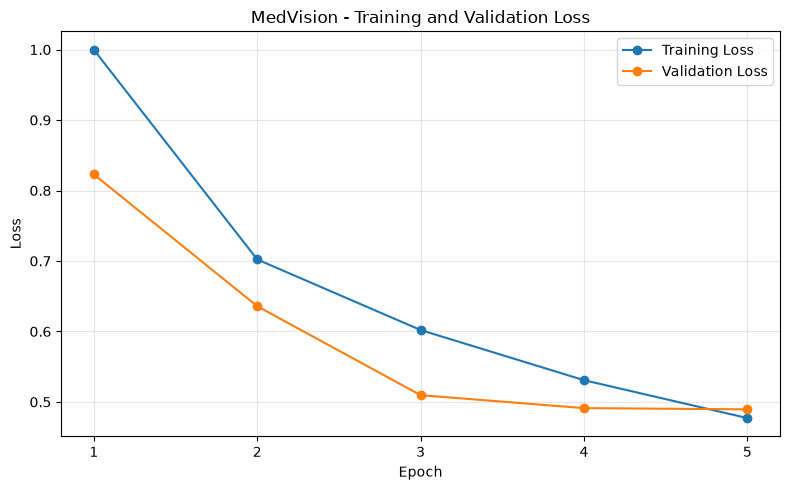

In [34]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    history_df["epoch"],
    history_df["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.title("MedVision - Training and Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.xticks(history_df["epoch"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(FIGURE_DIR / "baseline_loss.png", dpi=300)
plt.show()

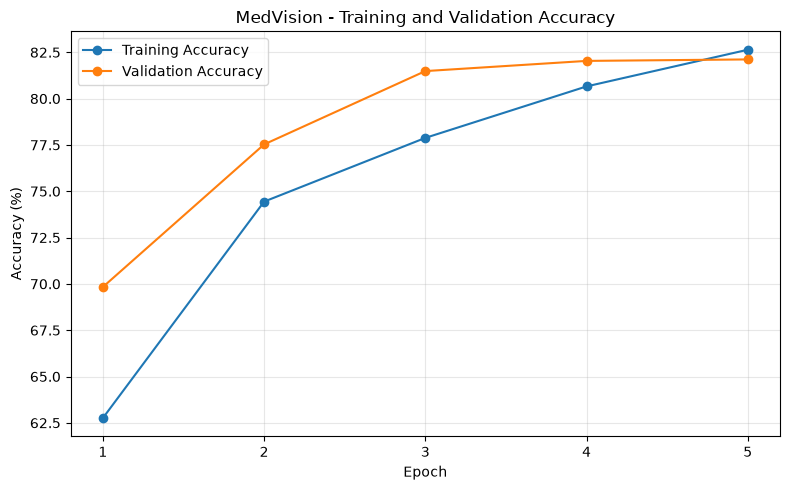

In [35]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["train_accuracy"] * 100,
    marker="o",
    label="Training Accuracy"
)

plt.plot(
    history_df["epoch"],
    history_df["val_accuracy"] * 100,
    marker="o",
    label="Validation Accuracy"
)

plt.title("MedVision - Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.xticks(history_df["epoch"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(FIGURE_DIR / "baseline_accuracy.png", dpi=300)
plt.show()

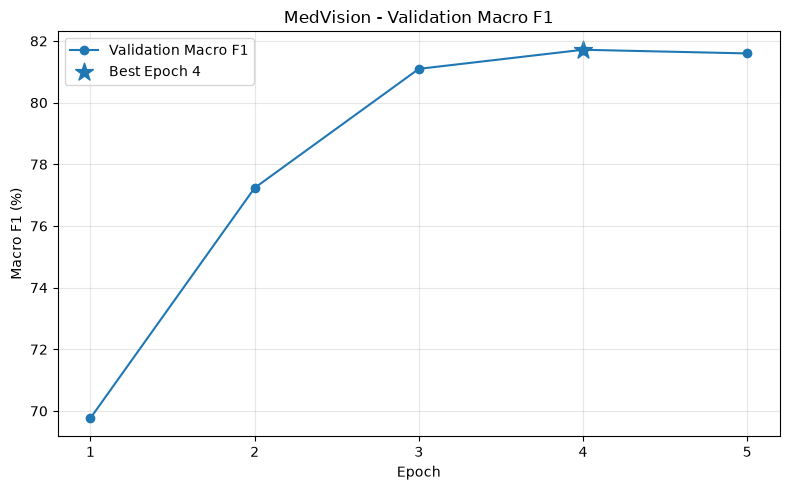

In [36]:
plt.figure(figsize=(8, 5))

plt.plot(
    history_df["epoch"],
    history_df["val_macro_f1"] * 100,
    marker="o",
    label="Validation Macro F1"
)

best_epoch = history_df["val_macro_f1"].idxmax() + 1
best_f1 = history_df["val_macro_f1"].max() * 100

plt.scatter(
    best_epoch,
    best_f1,
    marker="*",
    s=180,
    label=f"Best Epoch {best_epoch}"
)

plt.title("MedVision - Validation Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Macro F1 (%)")
plt.xticks(history_df["epoch"])
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(FIGURE_DIR / "baseline_macro_f1.png", dpi=300)
plt.show()

In [37]:
MODEL_PATH = PROJECT_ROOT / "models" / "medvision_cnn_baseline.pth"

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model checkpoint not found: {MODEL_PATH}")

model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)

model.eval()

print("Best baseline model loaded successfully!")
print("Best epoch:", best_epoch + 1 if False else 4)
print("Best validation Macro F1:", round(best_f1 / 100, 4))

Best baseline model loaded successfully!
Best epoch: 4
Best validation Macro F1: 0.8172


In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    confusion_matrix,
    classification_report,
    accuracy_score,
    f1_score
)

print("Evaluation libraries imported successfully!")

Evaluation libraries imported successfully!


In [39]:
class_names = [
    "Adipose",
    "Background",
    "Debris",
    "Lymphocytes",
    "Mucus",
    "Smooth Muscle",
    "Normal Colon Mucosa",
    "Cancer-associated Stroma",
    "Colorectal Adenocarcinoma Epithelium"
]

print("Number of classes:", len(class_names))

for index, name in enumerate(class_names):
    print(f"{index}: {name}")
    

Number of classes: 9
0: Adipose
1: Background
2: Debris
3: Lymphocytes
4: Mucus
5: Smooth Muscle
6: Normal Colon Mucosa
7: Cancer-associated Stroma
8: Colorectal Adenocarcinoma Epithelium


In [40]:
def get_predictions(model, data_loader, device):

    model.eval()

    all_predictions = []
    all_labels = []

    with torch.no_grad():

        for images, labels in data_loader:

            images = images.to(device)

            outputs = model(images)

            _, predictions = torch.max(outputs, 1)

            all_predictions.extend(
                predictions.cpu().numpy()
            )

            all_labels.extend(
                labels.numpy()
            )

    return np.array(all_labels), np.array(all_predictions)


val_labels, val_predictions = get_predictions(
    model,
    val_loader,
    device
)

print("Validation predictions generated successfully!")
print("Total validation labels:", len(val_labels))
print("Total predictions:", len(val_predictions))

Validation predictions generated successfully!
Total validation labels: 10004
Total predictions: 10004


In [41]:
cm = confusion_matrix(
    val_labels,
    val_predictions,
    labels=list(range(9))
)

print("Confusion matrix shape:", cm.shape)
print("\nConfusion Matrix:")
print(cm)

Confusion matrix shape: (9, 9)

Confusion Matrix:
[[1016    6    0    0   18    0    1    0    0]
 [  43  989    0    0   21    0    0    3    1]
 [   2    2  775   38    6  138   32  128   31]
 [   1    0    4 1138    0    0    7    4    2]
 [  44    9   11    3  708    5   82   21    7]
 [   9    1   71    0   18 1099    8  146    2]
 [   7    0   11   50   88    4  677    4   36]
 [   0    2  115    9   20  156   44  686   13]
 [   0    2   68   44   20   10  129   40 1119]]


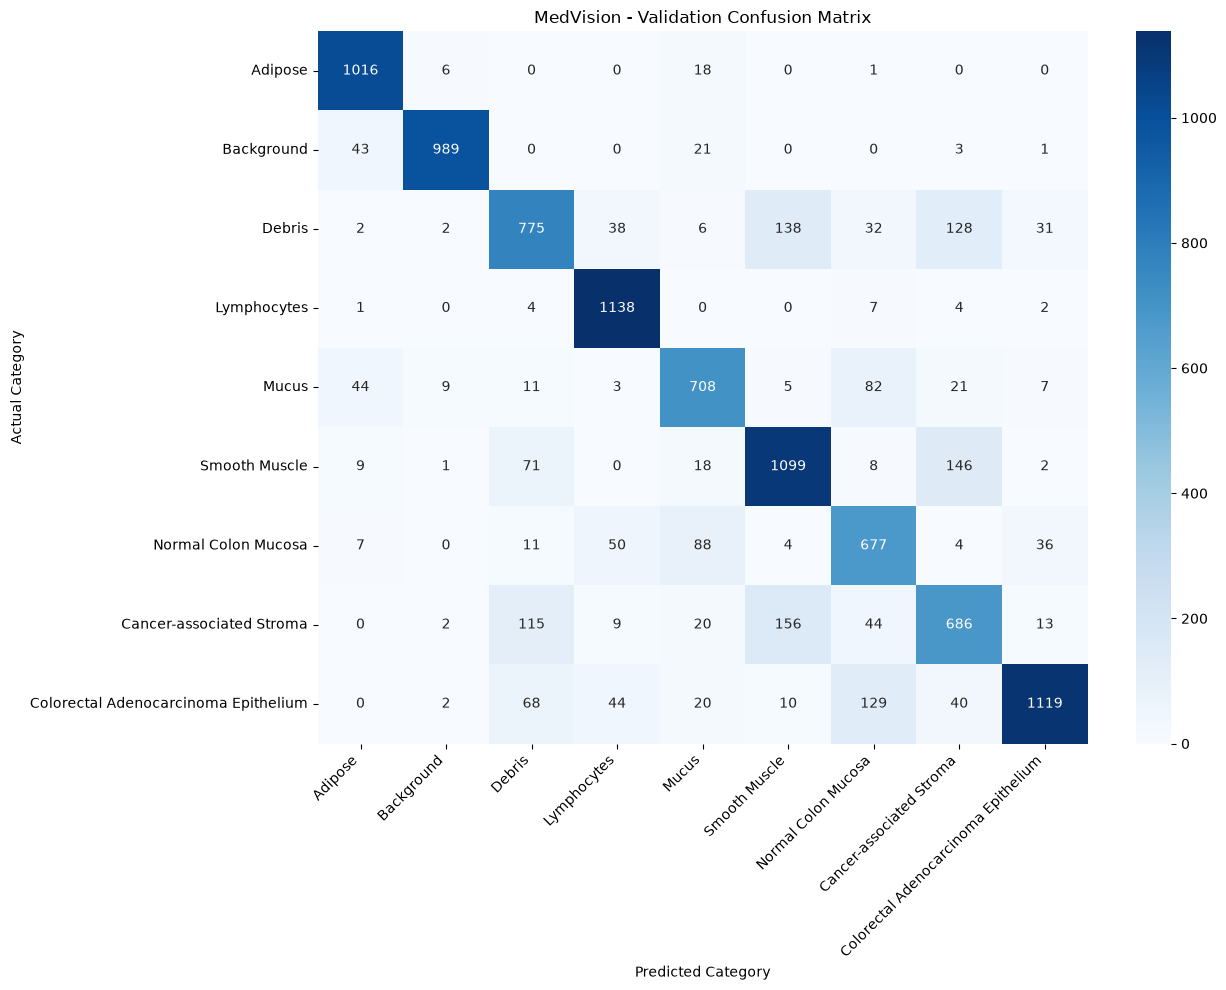

In [42]:
plt.figure(figsize=(13, 10))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MedVision - Validation Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "baseline_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [43]:
report = classification_report(
    val_labels,
    val_predictions,
    labels=list(range(9)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

report_df = pd.DataFrame(report).transpose()

print("MedVision - Validation Classification Report\n")

print(
    report_df.round(4).to_string()
)

MedVision - Validation Classification Report

                                      precision  recall  f1-score     support
Adipose                                  0.9055  0.9760    0.9394   1041.0000
Background                               0.9782  0.9357    0.9565   1057.0000
Debris                                   0.7346  0.6727    0.7023   1152.0000
Lymphocytes                              0.8877  0.9844    0.9336   1156.0000
Mucus                                    0.7875  0.7955    0.7915    890.0000
Smooth Muscle                            0.7783  0.8117    0.7946   1354.0000
Normal Colon Mucosa                      0.6908  0.7719    0.7291    877.0000
Cancer-associated Stroma                 0.6647  0.6565    0.6606   1045.0000
Colorectal Adenocarcinoma Epithelium     0.9240  0.7814    0.8468   1432.0000
accuracy                                 0.8204  0.8204    0.8204      0.8204
macro avg                                0.8168  0.8206    0.8172  10004.0000
weighted avg      

In [44]:
class_results = report_df.loc[
    class_names,
    ["precision", "recall", "f1-score"]
].copy()

class_results = class_results.sort_values(
    by="f1-score",
    ascending=False
)

print("Performance by tissue category:\n")

print(class_results.round(4).to_string())

print("\nBest performing category:")
print(class_results.index[0])

print("\nLowest performing category:")
print(class_results.index[-1])

Performance by tissue category:

                                      precision  recall  f1-score
Background                               0.9782  0.9357    0.9565
Adipose                                  0.9055  0.9760    0.9394
Lymphocytes                              0.8877  0.9844    0.9336
Colorectal Adenocarcinoma Epithelium     0.9240  0.7814    0.8468
Smooth Muscle                            0.7783  0.8117    0.7946
Mucus                                    0.7875  0.7955    0.7915
Normal Colon Mucosa                      0.6908  0.7719    0.7291
Debris                                   0.7346  0.6727    0.7023
Cancer-associated Stroma                 0.6647  0.6565    0.6606

Best performing category:
Background

Lowest performing category:
Cancer-associated Stroma


In [45]:
# Save classification report
report_df.to_csv(
    PROJECT_ROOT / "docs" / "baseline_classification_report.csv"
)

# Save confusion matrix
cm_df = pd.DataFrame(
    cm,
    index=class_names,
    columns=class_names
)

cm_df.to_csv(
    PROJECT_ROOT / "docs" / "baseline_confusion_matrix.csv"
)

# Save per-class results
class_results.to_csv(
    PROJECT_ROOT / "docs" / "baseline_class_performance.csv"
)

print("Baseline evaluation files saved successfully!")

Baseline evaluation files saved successfully!


In [46]:
MODEL_PATH = PROJECT_ROOT / "models" / "medvision_cnn_baseline.pth"

model.load_state_dict(
    torch.load(MODEL_PATH, map_location=device, weights_only=True)
)

model.eval()

print("Best baseline model loaded successfully!")
print("Evaluation device:", device)

Best baseline model loaded successfully!
Evaluation device: mps


In [47]:
test_labels, test_predictions = get_predictions(
    model,
    test_loader,
    device
)

print("Test labels:", len(test_labels))
print("Test predictions:", len(test_predictions))
print("Predictions generated successfully!")

Test labels: 7180
Test predictions: 7180
Predictions generated successfully!


In [48]:
test_accuracy = accuracy_score(test_labels, test_predictions)

test_macro_f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro"
)

test_weighted_f1 = f1_score(
    test_labels,
    test_predictions,
    average="weighted"
)

print("MedVision - Final Test Results")
print("-------------------------------")
print(f"Test Accuracy:   {test_accuracy:.4f}")
print(f"Test Macro F1:   {test_macro_f1:.4f}")
print(f"Test Weighted F1: {test_weighted_f1:.4f}")

MedVision - Final Test Results
-------------------------------
Test Accuracy:   0.8006
Test Macro F1:   0.7354
Test Weighted F1: 0.8021


In [49]:
test_report = classification_report(
    test_labels,
    test_predictions,
    labels=list(range(9)),
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

test_report_df = pd.DataFrame(test_report).transpose()

print("MedVision - Final Test Classification Report\n")
print(test_report_df.round(4).to_string())

MedVision - Final Test Classification Report

                                      precision  recall  f1-score    support
Adipose                                  0.9116  0.9716    0.9407  1338.0000
Background                               0.8573  1.0000    0.9232   847.0000
Debris                                   0.2605  0.4041    0.3168   339.0000
Lymphocytes                              0.7759  0.9558    0.8565   634.0000
Mucus                                    0.9295  0.7266    0.8156  1035.0000
Smooth Muscle                            0.6176  0.6030    0.6103   592.0000
Normal Colon Mucosa                      0.7753  0.7868    0.7810   741.0000
Cancer-associated Stroma                 0.6481  0.4157    0.5065   421.0000
Colorectal Adenocarcinoma Epithelium     0.9438  0.8037    0.8682  1233.0000
accuracy                                 0.8006  0.8006    0.8006     0.8006
macro avg                                0.7466  0.7408    0.7354  7180.0000
weighted avg                  

In [50]:
test_cm = confusion_matrix(
    test_labels,
    test_predictions,
    labels=list(range(9))
)

print("Test Confusion Matrix:")
print(test_cm)

Test Confusion Matrix:
[[1300    4   13    0    5   16    0    0    0]
 [   0  847    0    0    0    0    0    0    0]
 [   0    0  137    9    0  143    0   49    1]
 [   1    0    3  606    0    0   22    0    2]
 [ 118  137    1    3  752    0   20    2    2]
 [   0    0  131   55    0  357    0   42    7]
 [   6    0   39   50   41    3  583    1   18]
 [   0    0  117   18    7   56   19  175   29]
 [   1    0   85   40    4    3  108    1  991]]


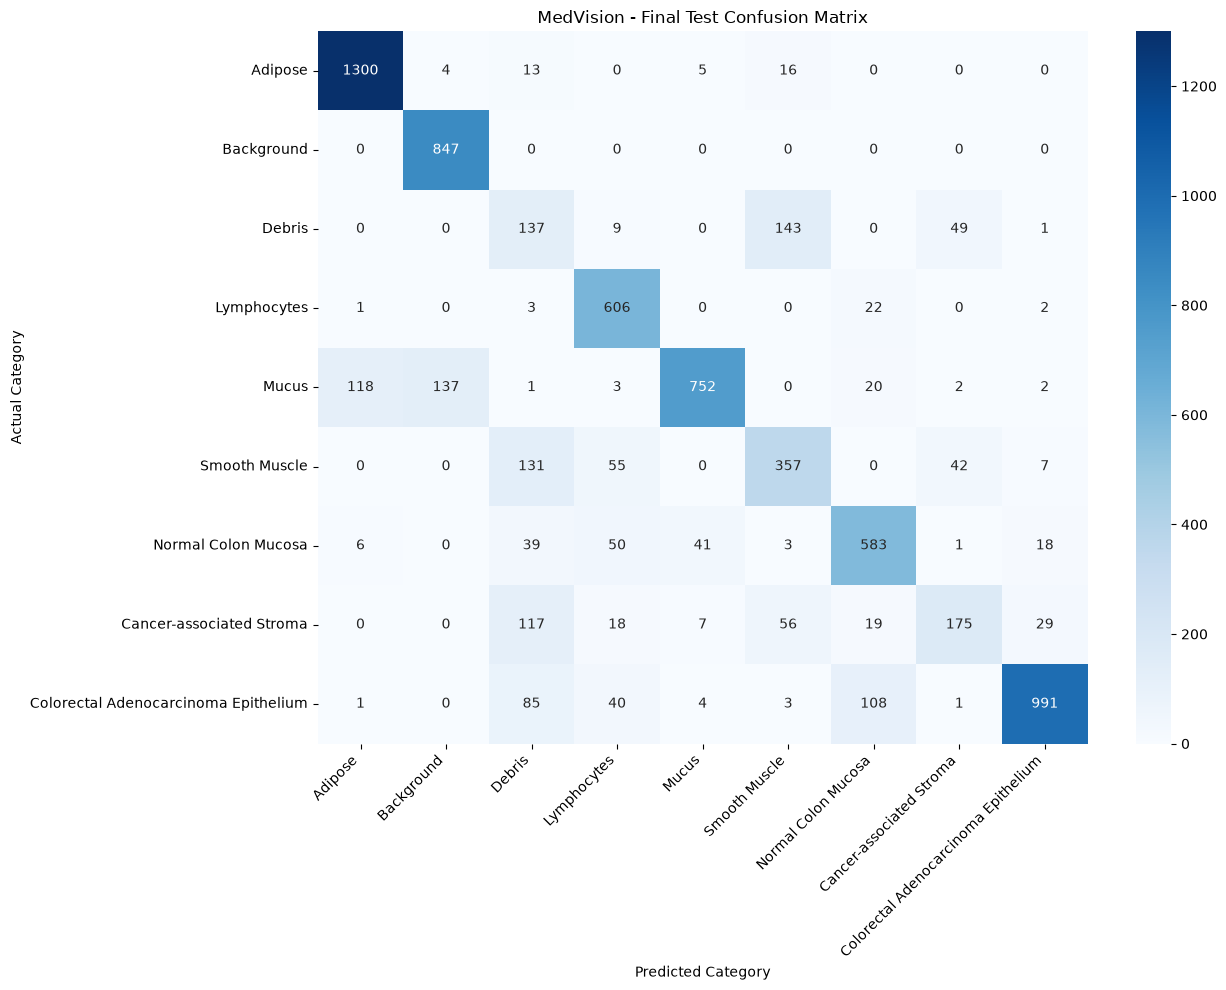

In [51]:
plt.figure(figsize=(13, 10))

sns.heatmap(
    test_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("MedVision - Final Test Confusion Matrix")
plt.xlabel("Predicted Category")
plt.ylabel("Actual Category")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "baseline_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [52]:
test_report_df.to_csv(
    PROJECT_ROOT / "docs" / "baseline_test_classification_report.csv"
)

test_cm_df = pd.DataFrame(
    test_cm,
    index=class_names,
    columns=class_names
)

test_cm_df.to_csv(
    PROJECT_ROOT / "docs" / "baseline_test_confusion_matrix.csv"
)

test_results = pd.DataFrame([{
    "test_accuracy": test_accuracy,
    "test_macro_f1": test_macro_f1,
    "test_weighted_f1": test_weighted_f1
}])

test_results.to_csv(
    PROJECT_ROOT / "docs" / "baseline_test_metrics.csv",
    index=False
)

print("Final test evaluation files saved successfully!")

Final test evaluation files saved successfully!
